# Logical QUOPS with CUDA-Q

Import one CUDA-Q BR kernel and lower it through P0, P1, P2 and P3 with ideal Steane implementations.



# P0: synthesize a logical BR





/opt/nvidia/cudaq/cudaq/__init__.py:282: UserWarning: cudaq-logical is in preview. Its APIs, behavior, and documentation may change substantially in upcoming versions.
  from . import logical  # noqa: F401


/tmp/ipykernel_9/677541.py:2: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  import cudaq


Peak logical qubits                 2
T and T-dagger operations           0
Total logical operations           39
Serial action-depth upper bound    39
Name: P0: before synthesis, dtype: int64

Peak logical qubits                  2
T and T-dagger operations          156
Total logical operations           482
Serial action-depth upper bound    482
Name: P0: after Clifford+T synthesis, dtype: int64

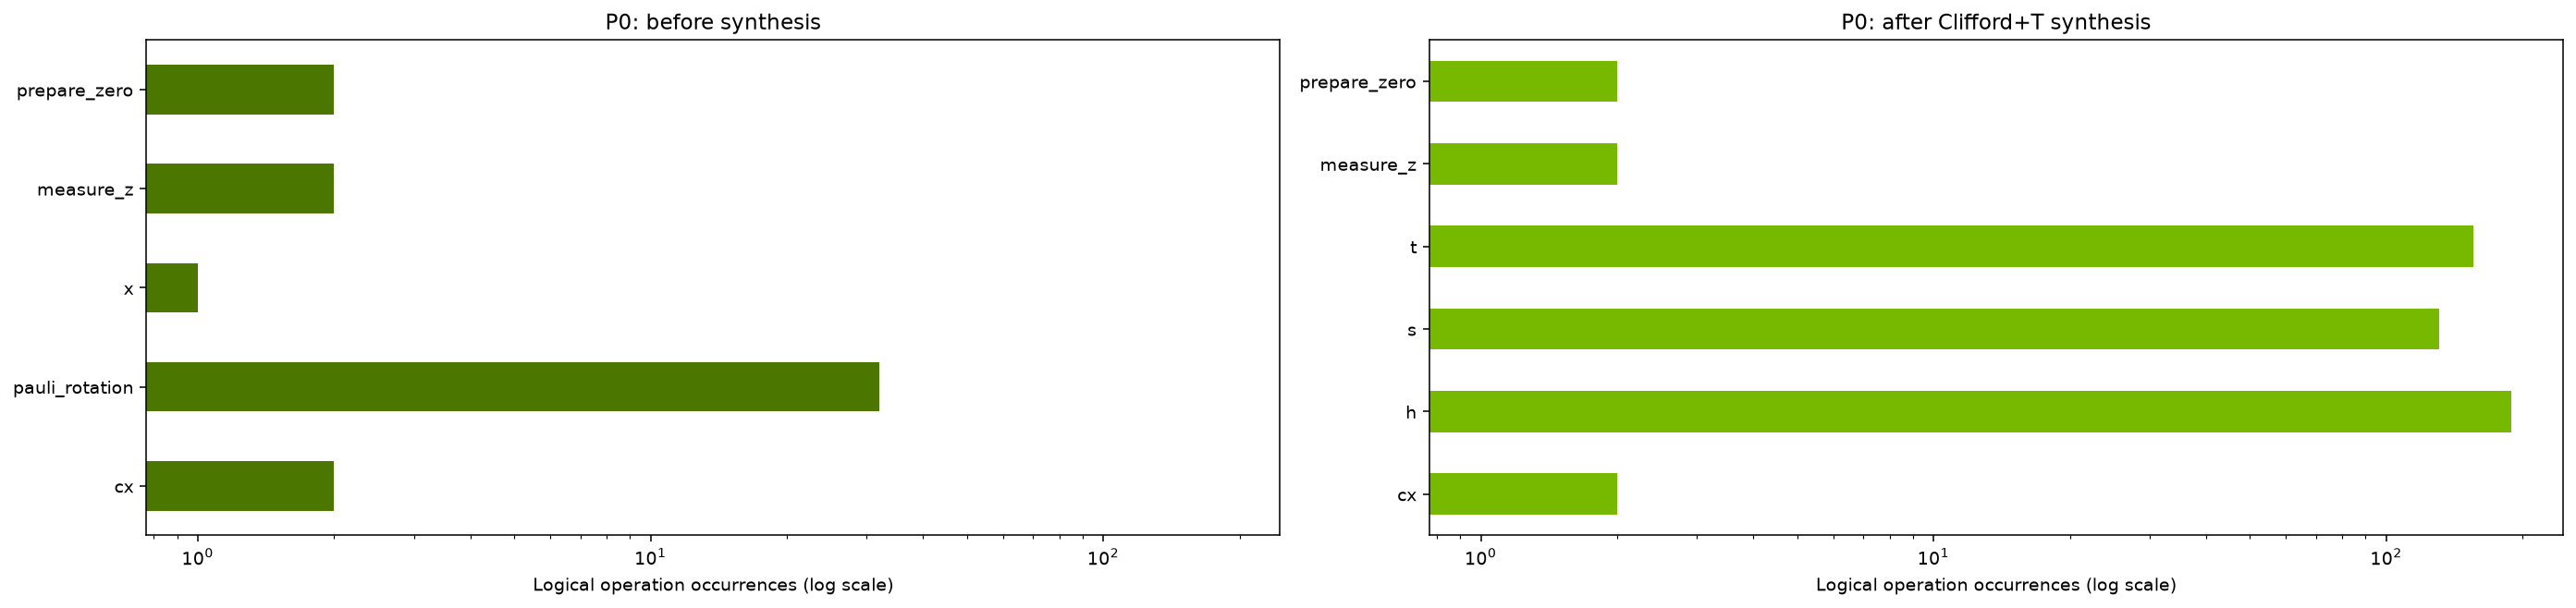

In [1]:
from typing import Callable
import cudaq
import cudaq.logical as cql
import pandas as pd
from IPython.display import display

from src import *

# Use one small QUOPS workload throughout synthesis, resource estimation and execution.
width, depth, zeta = 2, 2, 1.0
seed = 2026
gate_synthesis_precision = 1e-4

C = sample_quops_circuit(width, depth, zeta, seed=seed)
C_inverse = adjoint_C(C)
rc_C_inverse = randomized_compilation(C_inverse, seed=seed + 1, style="pauli_frame")
caps = sample_mcfe_caps(width, seed=seed + 2)
L, L_prime = caps.initial, caps.final

# Apply the four CUDA-Q component kernels in temporal order.
@cudaq.kernel
def BR(width: int, L: Callable[[cudaq.qview], None], C: Callable[[cudaq.qview], None], rc_C_inverse: Callable[[cudaq.qview], None], L_prime: Callable[[cudaq.qview], None]):
    qubits = cudaq.qvector(width)
    L(qubits)
    C(qubits)
    rc_C_inverse(qubits)
    L_prime(qubits)
    mz(qubits)

# Import this CUDA-Q kernel directly into P0 without authoring a logical program.
source_p0 = cql.compiler.import_cudaq(BR, width, L, C, rc_C_inverse, L_prime, optimization_level=0)
p0 = cql.compiler.synthesize(source_p0, gate_set=cql.compiler.gate_sets.clifford_t, precision=gate_synthesis_precision)
resources = cql.estimate(p0, tier=cql.estimate.Tier.LOGICAL)
source_resources = cql.estimate(source_p0, tier=cql.estimate.Tier.LOGICAL)
fig = plot_p0_comparison(source_resources, resources)


### Saved study 2: synthesis precision

The three panels show **Clifford gates**, **T/T-dagger gates**, and their **combined count** in the complete synthesized BR. Each curve represents one width/depth pair. Moving right reduces the per-rotation approximation tolerance from $10^{-2}$ toward $10^{-6}$, requiring more gates to approximate the rotations more closely.

Lines show medians across circuit seeds; shaded bands show the 10th–90th percentiles across those seeds. The bands describe variation between circuits. Counts exclude preparation and readout. The precision is a compiler tolerance for each rotation, not a measured circuit error rate.

![P0 Clifford, T and combined gate counts versus synthesis precision](plots/p0_br_precision_distinct.png)


## 5. P1: place the logical qubits

The device has one **compute region** with $w$ logical slots and readout support. All $w$ BR owners are placed together in this region.

The table and plot report occupied and free logical slots. Placement does not estimate routing or execution time.


placed_owners          2
regions_used           1
relaxed_preferences    0
Name: P1 placement, dtype: int64

,region,capacity,occupied,free
0,compute,2,2,0


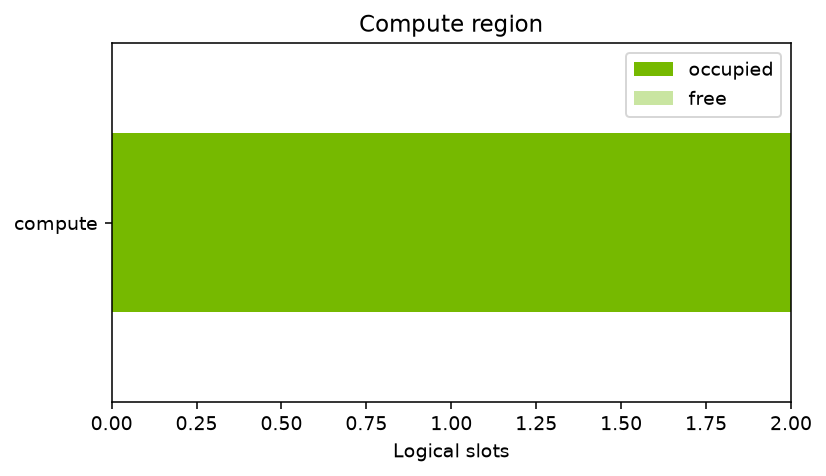

In [2]:
# Declare capacity in logical slots; physical carriers are introduced by the P2 encoding.
builder = cql.devices.DeviceBuilder("QUOPSDevice")
builder.logical.add_compute(name="compute", capacity=width, capabilities=(cql.architecture.capability.logical_measurement,))
builder.logical.add_stream(cql.std.T_STATE, name="t_states", external=True) # State production and delivery costs are outside this model.
device = builder.build()

# Collect P0 logical owners; placement maps these identities to compute slots.
owners = tuple(value for group in p0.values for value in group)

# Keep interacting owners together and require logical readout.
placement_constraints = (cql.architecture.colocate(owners), cql.architecture.require_capability(cql.architecture.capability.logical_measurement), cql.architecture.prefer(space=device.logical.compute, for_=cql.architecture.lifecycle.ACTIVE))
p1 = cql.compiler.place(p0, device=device, placement=placement_constraints)

# Inspect the placed owners and the occupied/free slots in the compute region.
placement_metrics = pd.Series({"placed_owners": len(p1.placement.bindings), "regions_used": len({binding.space for binding in p1.placement.bindings}), "relaxed_preferences": len(p1.placement.relaxed_preferences)}, name="P1 placement")
capacity = pd.DataFrame([{"region": device.logical.compute.name, "capacity": device.logical.compute.capacity, "occupied": len({binding.slot for binding in p1.placement.bindings})}])
capacity["free"] = capacity["capacity"] - capacity["occupied"]
display(placement_metrics, capacity)

# Show logical capacity for the single compute region.
fig = plot_p1_capacity(capacity)


## 6. P2: encode qubits and implement Cliffords

Steane $[[7,1,3]]$ stores **one logical qubit in seven data qubits**, plus reserved syndrome ancillas. A gadget supplies a typed encoded operation.

For the installed convention,

$$H_L\doteq H^{\otimes7},\qquad S_L\doteq(S^\dagger)^{\otimes7},$$

where $\doteq$ denotes equality on the code space up to phase. CX acts transversally between corresponding data carriers. These implementations alone do not prove circuit-level fault tolerance.


In [3]:
code = cql.codes.Steane # One logical qubit per block, with seven data carriers and reserved syndrome ancillas.

# implements names the logical operation; patch[Steane] fixes its encoded boundary.
# Gadgets return live blocks that callers pass to subsequent operations.
@cql.gadget(implements=cql.std.h)
def steane_h(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    return cql.h(block.data) # Apply H to all seven data carriers.

@cql.gadget(implements=cql.std.s)
def steane_s(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    return cql.sdg(block.data) # Physical S-dagger implements logical S.

@cql.gadget(implements=cql.std.sdg)
def steane_sdg(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    return cql.s(block.data) # Physical S implements logical S-dagger.

@cql.gadget(implements=cql.std.cx)
def steane_cx(control: cql.patch[cql.codes.Steane], target: cql.patch[cql.codes.Steane]) -> tuple[cql.patch[cql.codes.Steane], cql.patch[cql.codes.Steane]]:
    return cql.cx(control.data, target.data) # Pair corresponding data carriers.


## 7. P2: implement T with a magic state

The protocol consumes one externally supplied encoded state,

$$|A_L\rangle=T_L|+_L\rangle=\frac{|0_L\rangle+e^{i\pi/4}|1_L\rangle}{\sqrt2}.$$

Apply CX from data to ancilla, measure the ancilla in Z, and apply $S_L$ to the surviving data when the result is 1: $S_LT_L^\dagger=T_L$. Appending $S_L^\dagger$ implements T-dagger.

The estimate excludes magic-state production and delivery.


In [4]:
# Specialize destructive logical Z readout to the selected code.
steane_measure_z = cql.gadgets.measure_z(code)

@cql.protocol(implements=cql.std.t)
def steane_t(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    # Request one externally supplied encoded magic state and expose its ancilla block.
    magic, = cql.request_many(cql.std.T_STATE, count=1)
    block, ancilla = cql.unpack_resource(magic, like=block, encoding=cql.codes.Steane) # Expose the encoded ancilla while retaining the data block.
    block, ancilla = steane_cx(block, ancilla)
    measured = steane_measure_z(ancilla) # Consume the ancilla and obtain the logical Z bit.

    # Apply S for outcome 1; carries keeps the data block available after either branch.
    block, = cql.ops.cond(measured, then=lambda block: steane_s(block), else_=lambda block: block, carries=(block,))
    return block

@cql.protocol(implements=cql.std.tdg)
def steane_tdg(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    return steane_sdg(steane_t(block)) # S-dagger after T implements T-dagger.


## 8. P2: count encoded resources

For the complete BR,

$$N_A=N_T+N_{T^\dagger},\qquad N_{\rm data}=7B_{\rm peak}.$$

$N_A$ is magic-state demand and $B_{\rm peak}$ is the modeled peak of live Steane blocks. Serial injection needs the $w$ data blocks plus one active encoded magic-state block when T states are used. Templates also reserve ancillas; capacity and live usage are different quantities.

The compiler counts **static instructions and both conditional branches**, rather than individual physical gates or execution time. Its reported `patches_peak` omits the active encoded magic-state block in this preview, so the table gives the modeled total separately. External factories are excluded. This compilation is the zero-syndrome-round baseline.


In [5]:
# Supply preparation, readout and gate implementations needed by the synthesized BR.
realizations = (cql.gadgets.prepare_zero(code), steane_measure_z, steane_h, steane_s, steane_sdg, steane_cx, steane_t, steane_tdg)

# Link each logical operation to its encoded gadget or protocol.
architecture = cql.devices.QECArchitecture("SteaneArchitecture", code.default_encoding, link_roots=realizations)
builder = cql.devices.DeviceBuilder(device.name, logical=device.logical)

# Bind compute to Steane and reserve one additional block for T-state injection.
builder.qec.bind(builder.logical.compute, architecture=architecture, block_capacity=width + 1)
p2_device = builder.build()

# Lower the exact P1 program using the selected QEC implementations.
p2 = cql.compile(p1, device=p2_device, pipeline=cql.compiler.pipelines.qec())

# Static estimates count vector instructions and both branches; one instruction may address many carriers.
p2_resources = cql.estimate(p2, tier=cql.estimate.Tier.STATIC)

# Retain the zero-round baseline so the next cell can isolate syndrome-extraction cost.
p2_baseline, baseline_resources = p2, p2_resources

# The serial injection model keeps one encoded magic block beside the live data blocks.
required_blocks = width + int(p2_resources.operation_counts.get("resource_request", 0) > 0)
p2_summary = pd.Series({"T-state requests": p2_resources.operation_counts.get("resource_request", 0), "syndrome extractions": p2_resources.syndrome_rounds, "compiler-reported peak patches": p2_resources.patches_peak, "modeled data and injection blocks": required_blocks, "carriers in these block templates": required_blocks * code.block.size}, name="P2 resources")
p2_instructions = pd.Series(p2_resources.operation_counts, name="static instruction occurrences").rename_axis("instruction").sort_index()
display(p2_summary, p2_instructions)


T-state requests                     156
syndrome extractions                   0
compiler-reported peak patches         2
modeled data and injection blocks      3
carriers in these block templates     39
Name: P2 resources, dtype: int64

instruction
alloc                 2
call                950
cx                  158
dealloc             158
event_await         156
h                   189
if                  156
measure_product     158
prep_z                2
resource_request    156
sdg                 287
unpack_resource     156
Name: static instruction occurrences, dtype: int64

## 9. P2: add one syndrome round

Extract all Steane checks from the surviving data block **once after each T or T-dagger**, including its injection correction:

$$N_{\rm extraction}=N_T+N_{T^\dagger}=N_A.$$

Reuse the same P1 program and report the added work over the baseline. Magic-state demand stays fixed. Syndromes are recorded; no syndrome-based recovery is applied.


In [6]:
@cql.gadget(implements=cql.std.idle)
def steane_checkpoint(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    block, syndrome = cql.extract_syndrome(block, record="checkpoint") # One extraction round; record all checks without recovery.
    return block

# Reuse T injection without registering another implementation of the logical T operation.
injection = cql.protocol(steane_t.provider, name="steane_injection_body")

@cql.protocol(implements=cql.std.t)
def t_with_checkpoint(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    block = injection(block)
    return steane_checkpoint(block)

@cql.protocol(implements=cql.std.tdg)
def tdg_with_checkpoint(block: cql.patch[cql.codes.Steane]) -> cql.patch[cql.codes.Steane]:
    block = steane_sdg(injection(block)) # Complete T-dagger before extracting the syndrome.
    return steane_checkpoint(block)

# Replace the T/T-dagger implementations and keep the same placed BR.
checkpoint_realizations = tuple(gadget for gadget in realizations if gadget not in (steane_t, steane_tdg)) + (t_with_checkpoint, tdg_with_checkpoint)
checkpoint_architecture = cql.devices.QECArchitecture("SteaneCheckpoint", code.default_encoding, link_roots=checkpoint_realizations)
builder = cql.devices.DeviceBuilder(device.name, logical=device.logical)
builder.qec.bind(builder.logical.compute, architecture=checkpoint_architecture, block_capacity=width + 1)
p2 = cql.compile(p1, device=builder.build(), pipeline=cql.compiler.pipelines.qec())
p2_resources = cql.estimate(p2, tier=cql.estimate.Tier.STATIC)

# Report this one-round BR and its added work; T_STATE is the only requested resource kind.
# The modeled block total includes the active encoded injection ancilla.
qec_metrics = pd.DataFrame([{"rounds_per_T": 1, "syndrome_extractions": p2_resources.syndrome_rounds, "T_state_requests": p2_resources.operation_counts.get("resource_request", 0), "static_instructions": p2_resources.total_operations, "additional_instructions": p2_resources.total_operations - baseline_resources.total_operations, "compiler_reported_peak_patches": p2_resources.patches_peak, "modeled_data_and_injection_blocks": required_blocks, "carriers_in_these_block_templates": required_blocks * code.block.size}]).set_index("rounds_per_T")
display(qec_metrics)


,syndrome_extractions,T_state_requests,static_instructions,additional_instructions,compiler_reported_peak_patches,modeled_data_and_injection_blocks,carriers_in_these_block_templates
rounds_per_T,,,,,,,
1,156,156,2670,1092,2,3,39


### Saved study 3: code-memory resources

**15 cases:** Steane and rotated-surface distances 3/5/7/9, each with **1/10/100 syndrome rounds** between one encoded-zero preparation and destructive Z-readout. These cases compare an encoded-memory workload.

**Left:** the stacked bars show data carriers and reserved ancillas in one code template. **Middle:** the curves count data/check interactions across all syndrome rounds, exposing how work grows with code size and the number of rounds. **Right:** the curves count static vector instructions; one such instruction can operate on many carriers.

![Code-template carriers, syndrome support incidences and memory instruction counts](plots/p2_code_memory.png)

Surface distance 3→9 increases data carriers **9→81** and data/check interactions per round **24→288**. Yet all five codes have $I(R)=4+7R$ static vector instructions, so their curves overlap in the right panel. Equal instruction totals can therefore hide different carrier-level work. These are resource counts for memory, not measured logical error rates or logical QUOPS scores.


## 10. P3: lower the QUOPS kernel to a physical circuit

Lower the same imported and synthesized BR used above: two logical qubits, paper depth 2 (one layer pair), sampled C size 4 and seed 2026. The expected q0-first output is given by `caps.target`. Clifford+T synthesis introduces approximation error.

The physical device uses the Steane data carriers without reserved syndrome carriers: two seven-qubit blocks and one reusable bare magic-state ancilla, 15 carriers in total. The code space is unchanged. There are no syndrome rounds or recovery in this run.

The resource estimates above assume externally supplied encoded magic states. The physical implementation instead prepares an ideal bare \(T|+\rangle\) state for each T gate and couples it to the Steane logical-Z support. Its measurement selects the logical-S correction. This supply is not fault tolerant and excludes distillation and delivery costs.


In [7]:
execution_code = cql.codes.CSSCode(name="QUOPSSteaneData", block=cql.codes.CSSBlock(data=7), d=3, hx=code.hx, hz=code.hz, lx=code.lx, lz=code.lz)
execution_measure_z = cql.gadgets.measure_z(execution_code)

@cql.gadget(implements=cql.std.prepare_zero)
def execution_zero(block: cql.patch[execution_code]) -> cql.patch[execution_code]:
    block = cql.ops.reset(block.data)
    for index in (3, 5, 6):
        block = cql.ops.h(block.data[index])
    for control, targets in ((3, (0, 1, 2)), (5, (0, 1, 4)), (6, (0, 2, 4))):
        for target in targets:
            block = cql.ops.cx(block.data[control], block.data[target])
    return block

@cql.gadget(implements=cql.std.h)
def execution_h(block: cql.patch[execution_code]) -> cql.patch[execution_code]:
    return cql.ops.h(block.data)

@cql.gadget(implements=cql.std.s)
def execution_s(block: cql.patch[execution_code]) -> cql.patch[execution_code]:
    return cql.ops.sdg(block.data)

@cql.gadget(implements=cql.std.sdg)
def execution_sdg(block: cql.patch[execution_code]) -> cql.patch[execution_code]:
    return cql.ops.s(block.data)

@cql.gadget(implements=cql.std.cx)
def execution_cx(control: cql.patch[execution_code], target: cql.patch[execution_code]) -> tuple[cql.patch[execution_code], cql.patch[execution_code]]:
    return cql.ops.cx(control.data, target.data)


In [8]:
@cql.gadget(implements=cql.std.prepare_plus)
def execution_bare_plus(block: cql.patch[cql.codes.BareQubit]) -> cql.patch[cql.codes.BareQubit]:
    block = cql.ops.reset(block.data)
    return cql.ops.h(block.data)
execution_bare_measure_z = cql.gadgets.measure_z(cql.codes.BareQubit)

@cql.gadget(implements=cql.std.t)
def execution_bare_t(block: cql.patch[cql.codes.BareQubit]) -> cql.patch[cql.codes.BareQubit]:
    return cql.ops.t(block.data)

@cql.gadget(implements=cql.std.cx)
def execution_magic_cx(block: cql.patch[execution_code], magic: cql.patch[cql.codes.BareQubit]) -> tuple[cql.patch[execution_code], cql.patch[cql.codes.BareQubit]]:
    return cql.ops.cx(block.data, magic.data, pairs=tuple((index, 0) for index in execution_code.lz[0]))

@cql.protocol
def execution_inject_t(block: cql.patch[execution_code]) -> tuple[cql.patch[execution_code], bool]:
    magic = execution_bare_t(execution_bare_plus(cql.ops.allocate_patch(cql.codes.BareQubit, region="magic")))
    block, magic = execution_magic_cx(block, magic)
    correction = execution_bare_measure_z(magic)
    block, = cql.ops.cond(correction, carries=(block,), then=lambda live: (execution_s(live),), else_=lambda live: (live,))
    return block, correction

@cql.protocol(implements=cql.std.t)
def execution_t(block: cql.patch[execution_code]) -> cql.patch[execution_code]:
    block, correction = execution_inject_t(block)
    return block

@cql.protocol(implements=cql.std.tdg)
def execution_tdg(block: cql.patch[execution_code]) -> cql.patch[execution_code]:
    return execution_sdg(execution_t(block))


In [9]:
execution_t_architecture = cql.devices.QECArchitecture("QUOPSExecutionT", execution_code.default_encoding, link_roots=(execution_zero, execution_h, execution_s, execution_sdg, execution_cx, execution_measure_z, execution_t, execution_tdg, execution_magic_cx))
execution_magic_architecture = cql.devices.QECArchitecture("QUOPSExecutionMagic", cql.codes.BareQubit.default_encoding, link_roots=(execution_bare_plus, execution_bare_t, execution_bare_measure_z))
execution_t_builder = cql.devices.DeviceBuilder("QUOPSExecutionIdealT", source_module=None)
execution_compute_region = execution_t_builder.qec.bind(execution_t_builder.logical.add_compute(name="compute", capacity=width, capabilities=(cql.architecture.capability.logical_measurement,)), architecture=execution_t_architecture)
execution_magic_region = execution_t_builder.qec.bind(execution_t_builder.logical.add_compute(name="magic", capacity=1), architecture=execution_magic_architecture)
execution_t_builder.physical.bind(execution_compute_region, to=execution_t_builder.physical.add_qubits(width * execution_code.block.size, native_actions=cql.architecture.physical_actions.clifford_set(), native_instruments=(cql.architecture.physical_instruments.MZ, cql.architecture.physical_instruments.MX, cql.architecture.physical_instruments.MPP)))
execution_t_builder.physical.bind(execution_magic_region, to=execution_t_builder.physical.add_qubits(1, native_actions=(*cql.architecture.physical_actions.clifford_set(), cql.architecture.physical_actions.T), native_instruments=(cql.architecture.physical_instruments.MZ, cql.architecture.physical_instruments.MX)))
execution_t_builder.physical.set_operating_point(timing={"cycle_ns": 1.0})
execution_t_device = execution_t_builder.build()

# Place the same P0 circuit on the executable device with its explicit ideal state supply.
execution_placement = (cql.architecture.colocate(owners), cql.architecture.require_capability(cql.architecture.capability.logical_measurement), cql.architecture.prefer(space=execution_t_device.logical.compute, for_=cql.architecture.lifecycle.ACTIVE))
execution_p1 = cql.compiler.place(p0, device=execution_t_device, placement=execution_placement)
execution_p2 = cql.compile(execution_p1, pipeline=cql.compiler.pipelines.qec(), device=execution_t_device)
br_p3 = cql.compile(execution_p2, pipeline=cql.compiler.pipelines.physical(), device=execution_t_device)


In [10]:
display(pd.DataFrame([{"stage": name, "profile": build.profile} for name, build in (("P0: imported BR", source_p0), ("P0: Clifford+T", p0), ("P1: execution placement", execution_p1), ("P2: execution QEC", execution_p2), ("P3: physical circuit", br_p3))]))

# The pinned preview needs its internal Quake adapter to launch a void P3 entry point.
from cudaq.kernel.kernel_decorator import _kernel_from_quake
cudaq.set_target("qpp-cpu")
cudaq.set_random_seed(20261104)
physical_BR = _kernel_from_quake(br_p3.to_quake())
execution_shots = 4
execution_results = [physical_BR(optimization_level=0) for _ in range(execution_shots)]
display(pd.Series({"completed_launches": len(execution_results), "target": cudaq.get_target().name, "logical_bits_returned": False}, name="P3 execution"))


,stage,profile
0,P0: imported BR,p0
1,P0: Clifford+T,p0
2,P1: execution placement,p1
3,P2: execution QEC,p2n
4,P3: physical circuit,p3


completed_launches             4
target                   qpp-cpu
logical_bits_returned      False
Name: P3 execution, dtype: object